# 03 - Posting density by period

Count posts per period, **with and without text**, and test whether the periods differ.

* Periods come from `config/phases.csv` (eight named periods from the research plan: Pre-COVID ... DSA era). **Edit that file or define your own periods
  below** - any table with `phase, start, end` works.
* A channel only counts from its first post on. Without this, channels that start later would make early periods look quiet.
* "without text" = posts with no text at all (photo / video / forward without caption). `has_text` is any non-blank text.
* Days are Europe/Berlin days.

In [1]:
%matplotlib inline
import os, warnings
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

from tg_ingestor.analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

DATA = os.environ.get("TG_DATA", "../storage/raw")            # folder with the exported .csv / .parquet files
FIG = Path(os.environ.get("TG_FIGURES", "../storage/figures"))  # every plot / table is also saved here
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
pl.Config.set_tbl_rows(40).set_tbl_cols(20).set_fmt_str_lengths(70)


def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

In [2]:
df = load_corpus(DATA)
PHASES = load_phases(os.environ.get("TG_PHASES"))
EVENTS = load_events(os.environ.get("TG_EVENTS"))
DATA_END = df["day"].max()
print(f"{df.height:,} posts, data until {DATA_END}")
PHASES

869,307 posts, data until 2026-10-21


phase,label,start,end
str,str,date,date
"""Pre-COVID""","""Pre-pandemic baseline (plan: Phase 1)""",2020-01-01,2020-03-21
"""COVID wave 1""","""First wave / Querdenken incubation (plan: Phase 2)""",2020-03-22,2020-08-31
"""COVID winter""","""Winter lockdowns / peak protest mobilization (plan: Phase 3)""",2020-09-01,2021-02-28
"""Vaccination""","""Vaccination campaigns / platform migration (plan: Phase 4)""",2021-03-01,2022-02-23
"""Ukraine war""","""Poly-crisis pivot: Ukraine war and energy insecurity (plan: Phase 5)""",2022-02-24,2022-12-31
"""Domestic crisis""","""Domestic discontent / Heating Act / X API paywall (plan: Phase 6)""",2023-01-01,2023-10-06
"""Middle East""","""Middle East conflict and radicalization (plan: Phase 7)""",2023-10-07,2024-02-16
"""DSA era""","""DSA enforcement / elections / Telegram policy change (plan: Phase 8)""",2024-02-17,2026-10-20


## 1. Posts per period

In [3]:
ps = period_summary(df, PHASES)
ps.select("phase", "label", "start", "end", "days", "n_channels", "n_posts", "n_text", "n_notext",
          pl.col("share_notext").round(3), pl.col("posts_per_day").round(1), pl.col("text_per_day").round(1),
          pl.col("notext_per_day").round(1), "channel_days", pl.col("posts_per_channel_day").round(2))

phase,label,start,end,days,n_channels,n_posts,n_text,n_notext,share_notext,posts_per_day,text_per_day,notext_per_day,channel_days,posts_per_channel_day
str,str,date,date,i64,u32,u32,u32,u32,f64,f64,f64,f64,i64,f64
"""Pre-COVID""","""Pre-pandemic baseline (plan: Phase 1)""",2020-01-01,2020-03-21,81,7,10454,9750,704,0.067,129.1,120.4,8.7,566,18.47
"""COVID wave 1""","""First wave / Querdenken incubation (plan: Phase 2)""",2020-03-22,2020-08-31,163,10,38532,36497,2035,0.053,236.4,223.9,12.5,1423,27.08
"""COVID winter""","""Winter lockdowns / peak protest mobilization (plan: Phase 3)""",2020-09-01,2021-02-28,181,12,62127,57123,5004,0.081,343.2,315.6,27.6,1959,31.71
"""Vaccination""","""Vaccination campaigns / platform migration (plan: Phase 4)""",2021-03-01,2022-02-23,360,15,128254,115809,12445,0.097,356.3,321.7,34.6,4712,27.22
"""Ukraine war""","""Poly-crisis pivot: Ukraine war and energy insecurity (plan: Phase 5)""",2022-02-24,2022-12-31,311,16,127191,111130,16061,0.126,409.0,357.3,51.6,4958,25.65
"""Domestic crisis""","""Domestic discontent / Heating Act / X API paywall (plan: Phase 6)""",2023-01-01,2023-10-06,279,18,99630,87941,11689,0.117,357.1,315.2,41.9,4728,21.07
"""Middle East""","""Middle East conflict and radicalization (plan: Phase 7)""",2023-10-07,2024-02-16,133,18,53386,47382,6004,0.112,401.4,356.3,45.1,2394,22.3
"""DSA era""","""DSA enforcement / elections / Telegram policy change (plan: Phase 8)""",2024-02-17,2026-10-20,977,19,349708,304307,45401,0.13,357.9,311.5,46.5,18527,18.88


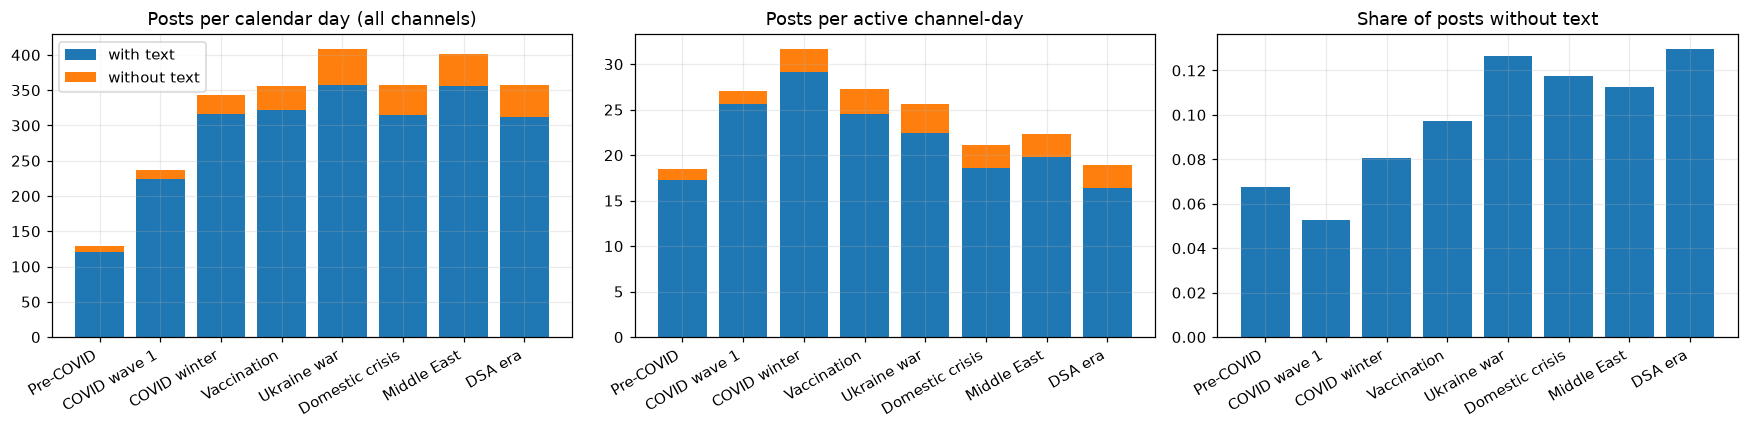

In [4]:
p = ps.to_pandas()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(p["phase"], p["text_per_day"], label="with text"); axes[0].bar(p["phase"], p["notext_per_day"], bottom=p["text_per_day"], label="without text")
axes[0].set_title("Posts per calendar day (all channels)"); axes[0].legend()
axes[1].bar(p["phase"], p["text_per_channel_day"], label="with text"); axes[1].bar(p["phase"], p["notext_per_channel_day"], bottom=p["text_per_channel_day"], label="without text")
axes[1].set_title("Posts per active channel-day")
axes[2].bar(p["phase"], p["share_notext"]); axes[2].set_title("Share of posts without text"); axes[2].set_ylim(0, None)
for a in axes: plt.setp(a.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); savefig("03_posts_per_phase"); plt.show()

## 2. Channel x period

Posts per active day, for all posts, posts with text and posts without text. Empty cells = the channel did not exist yet (or was inactive) in that period.

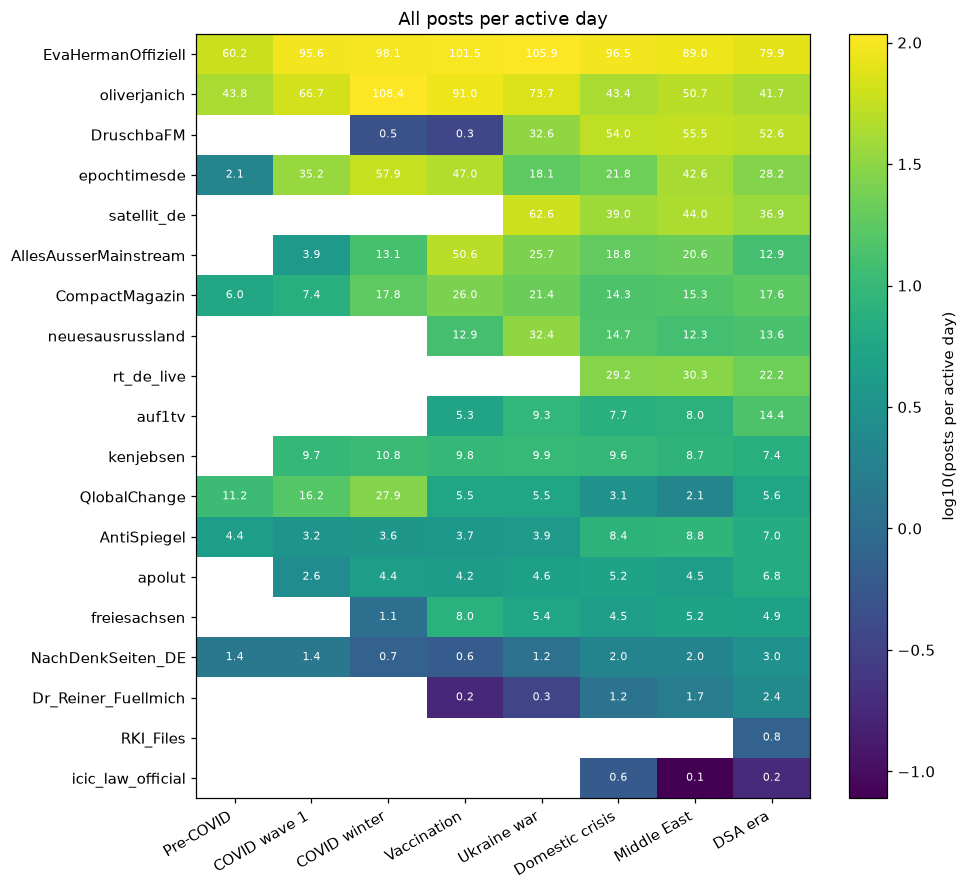

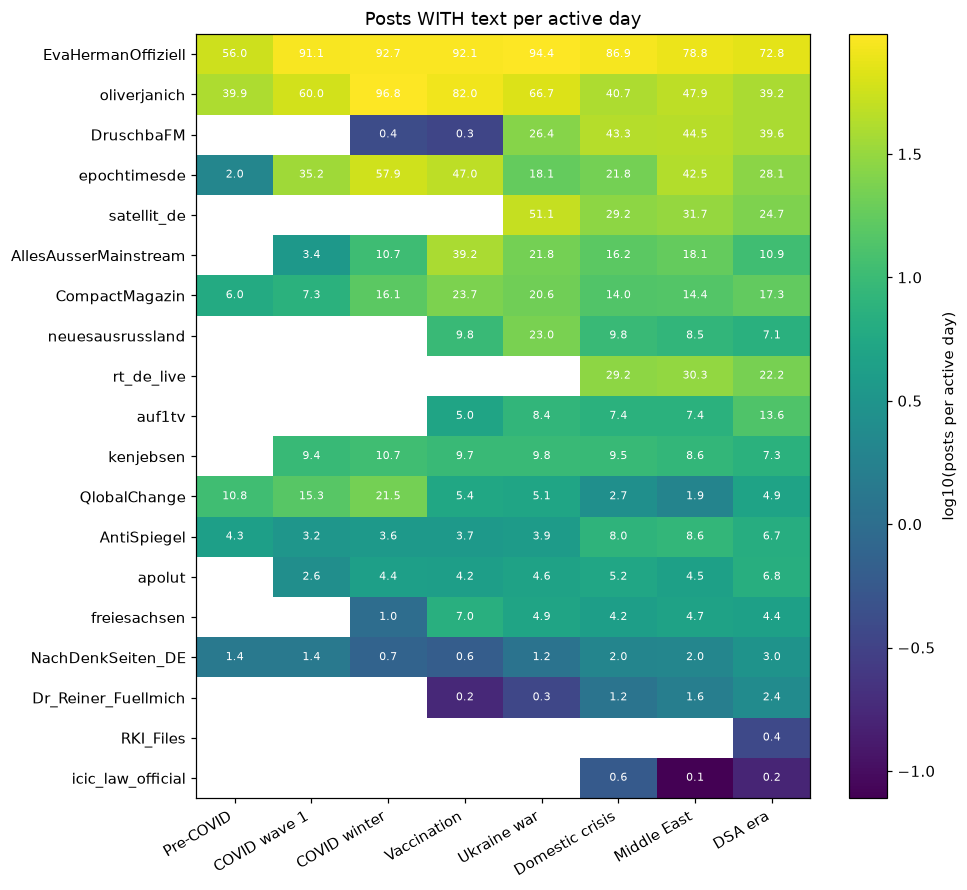

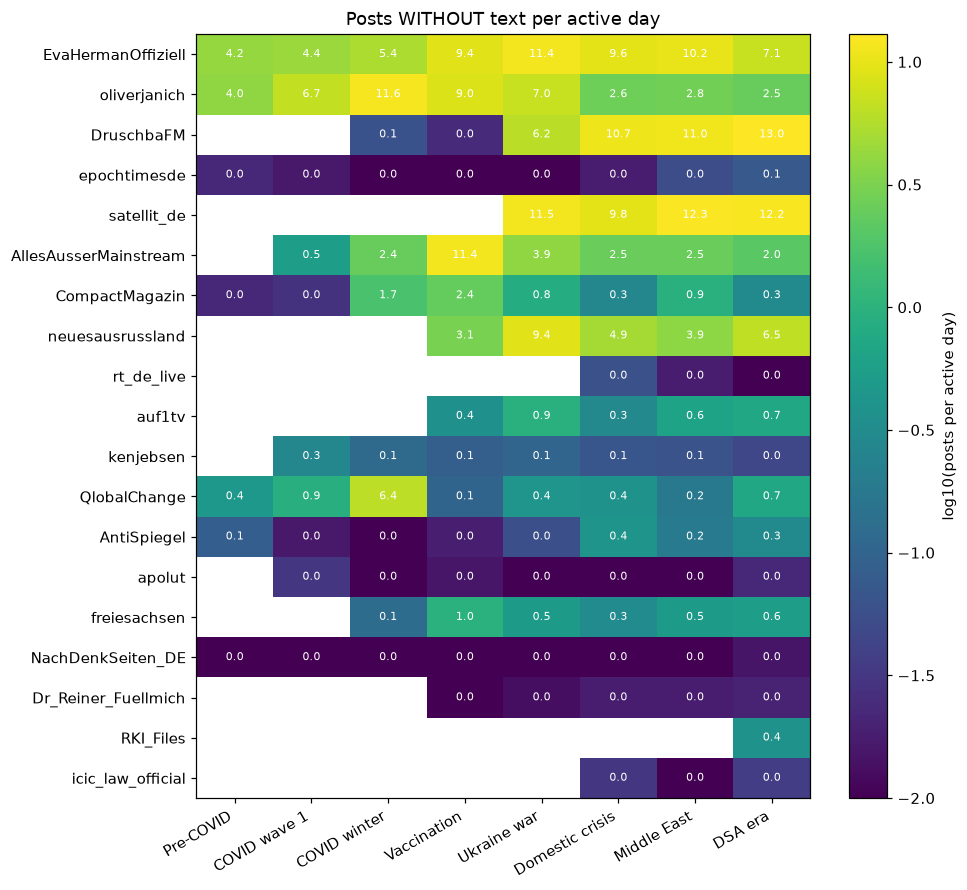

In [6]:
pc = period_summary(df, PHASES, by_channel=True)
order = df.group_by("channel").len().sort("len", descending=True)["channel"].to_list()

def heat(col, title, name):
    m = pc.to_pandas().pivot(index="channel", columns="phase", values=col).reindex(order)[PHASES["phase"].to_list()]
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(m) + 1.8))
    im = ax.imshow(np.log10(m.to_numpy().astype(float) + 0.01), aspect="auto", cmap="viridis"); ax.grid(False)
    ax.set_yticks(range(len(m)), m.index); ax.set_xticks(range(len(m.columns)), m.columns, rotation=30, ha="right")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iloc[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white")
    plt.colorbar(im, label="log10(posts per active day)"); ax.set_title(title); savefig(name); plt.show()
    return m

_ = heat("posts_per_channel_day", "All posts per active day", "03_heat_all")
_ = heat("text_per_channel_day", "Posts WITH text per active day", "03_heat_text")
_ = heat("notext_per_channel_day", "Posts WITHOUT text per active day", "03_heat_notext")

In [7]:
pc.select("channel", "phase", "channel_days", "n_posts", "n_text", "n_notext",
          pl.col("share_notext").round(3), pl.col("posts_per_channel_day").round(2)).sort("channel", "phase")

channel,phase,channel_days,n_posts,n_text,n_notext,share_notext,posts_per_channel_day
str,str,i64,u32,u32,u32,f64,f64
"""AllesAusserMainstream""","""COVID wave 1""",55,217,188,29,0.134,3.95
"""AllesAusserMainstream""","""COVID winter""",181,2378,1935,443,0.186,13.14
"""AllesAusserMainstream""","""DSA era""",977,12645,10652,1993,0.158,12.94
"""AllesAusserMainstream""","""Domestic crisis""",279,5233,4527,706,0.135,18.76
"""AllesAusserMainstream""","""Middle East""",133,2740,2409,331,0.121,20.6
"""AllesAusserMainstream""","""Pre-COVID""",0,0,0,0,null,null
"""AllesAusserMainstream""","""Ukraine war""",311,8003,6795,1208,0.151,25.73
"""AllesAusserMainstream""","""Vaccination""",360,18223,14123,4100,0.225,50.62
"""AntiSpiegel""","""COVID wave 1""",163,528,527,1,0.002,3.24


## 3. Weekly curves with periods and events

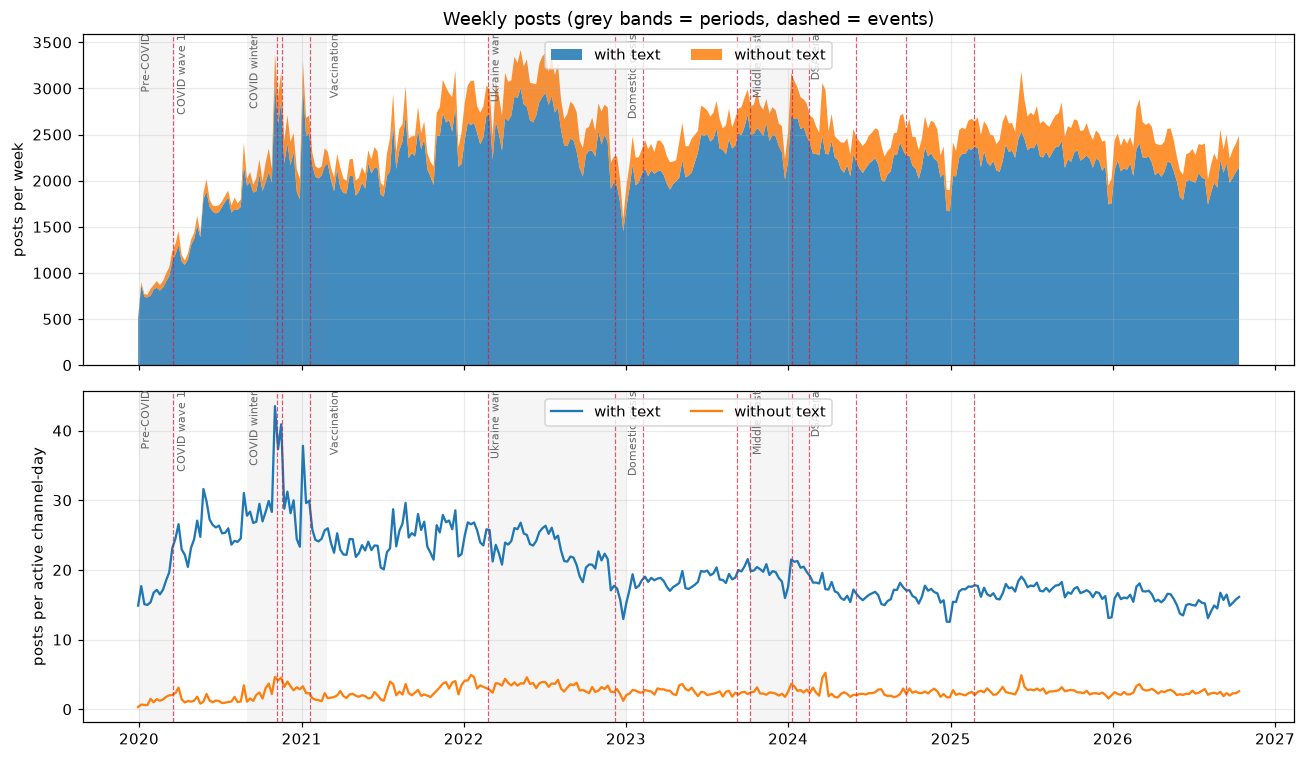

In [8]:
daily = daily_counts(df, by=())
sers = {k: to_series(daily, k) for k in ("n", "n_text", "n_notext")}
wk = pd.DataFrame(sers).resample("W-MON", label="left", closed="left").sum().iloc[:-1]   # drop the unfinished last week
active = (daily_counts(df).group_by("day").agg(pl.len().alias("active")).sort("day").to_pandas().set_index("day")["active"])
active.index = pd.to_datetime(active.index)
act_w = active.resample("W-MON", label="left", closed="left").sum().iloc[:-1]       # channel-days in the week

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].stackplot(wk.index, wk["n_text"], wk["n_notext"], labels=["with text", "without text"], alpha=0.85)
axes[0].set_ylabel("posts per week"); axes[0].legend(loc="upper center", ncols=2)
axes[1].plot(wk.index, (wk["n_text"] / act_w), label="with text"); axes[1].plot(wk.index, (wk["n_notext"] / act_w), label="without text")
axes[1].set_ylabel("posts per active channel-day"); axes[1].legend(loc="upper center", ncols=2)
for ax in axes:
    shade_phases(ax, PHASES); mark_events(ax, EVENTS)
axes[0].set_title("Weekly posts (grey bands = periods, dashed = events)"); plt.tight_layout()
savefig("03_weekly_density"); plt.show()

## 4. Your own periods

`period_summary` takes any table with `phase, start, end`. Two examples: a custom window around an event, and
automatic calendar quarters. To make periods permanent, edit `config/phases.csv`.

In [9]:
custom = pl.DataFrame({
    "phase": ["UKR_pre21d", "UKR_post21d", "LEIPZIG_pre14d", "LEIPZIG_post14d"],
    "label": ["21 days before invasion", "21 days after invasion", "14 days before Leipzig", "14 days after Leipzig"],
    "start": [date(2022, 2, 3), date(2022, 2, 24), date(2020, 10, 24), date(2020, 11, 7)],
    "end": [date(2022, 2, 23), date(2022, 3, 16), date(2020, 11, 6), date(2020, 11, 20)],
})
period_summary(df, custom).select("phase", "days", "n_posts", "n_text", "n_notext", pl.col("share_notext").round(3),
                                  pl.col("posts_per_day").round(1), pl.col("posts_per_channel_day").round(2))

phase,days,n_posts,n_text,n_notext,share_notext,posts_per_day,posts_per_channel_day
str,i64,u32,u32,u32,f64,f64,f64
"""LEIPZIG_pre14d""",14,5173,4757,416,0.08,369.5,36.95
"""LEIPZIG_post14d""",14,6216,5592,624,0.1,444.0,44.4
"""UKR_pre21d""",21,8305,7322,983,0.118,395.5,27.14
"""UKR_post21d""",21,8721,7796,925,0.106,415.3,27.42


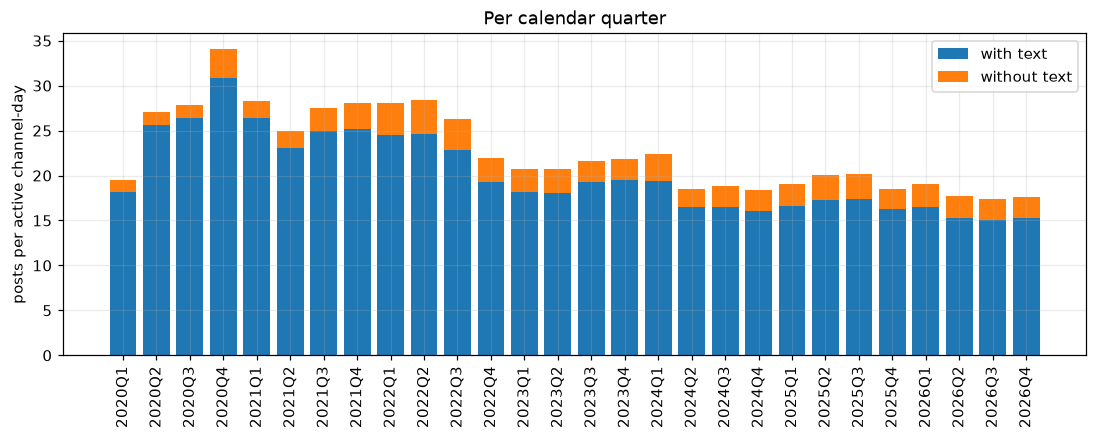

phase,n_posts,n_text,n_notext,share_notext,posts_per_channel_day
str,u32,u32,u32,f64,f64
"""2020Q1""",12400,11525,875,0.071,19.5
"""2020Q2""",19990,18992,998,0.05,27.01
"""2020Q3""",25415,24079,1336,0.053,27.84
"""2020Q4""",32669,29556,3113,0.095,34.1
"""2021Q1""",30399,28278,2121,0.07,28.33
"""2021Q2""",28039,25889,2150,0.077,24.97
"""2021Q3""",32915,29908,3007,0.091,27.52
"""2021Q4""",35208,31586,3622,0.103,28.1
"""2022Q1""",37249,32518,4731,0.127,28.09


In [10]:
quarters = quarterly_periods(df["day"].min(), DATA_END)
qs = period_summary(df, quarters, data_end=DATA_END).filter(pl.col("n_posts") > 0)
q = qs.to_pandas()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(q["phase"], q["text_per_channel_day"], label="with text"); ax.bar(q["phase"], q["notext_per_channel_day"], bottom=q["text_per_channel_day"], label="without text")
ax.set_xticks(range(len(q)), q["phase"], rotation=90); ax.set_ylabel("posts per active channel-day"); ax.legend()
ax.set_title("Per calendar quarter"); savefig("03_quarters"); plt.show()
qs.select("phase", "n_posts", "n_text", "n_notext", pl.col("share_notext").round(3), pl.col("posts_per_channel_day").round(2))

## 5. Weekday effect

Weekend posting drops. Any period comparison or event study has to control for this (the models below do).

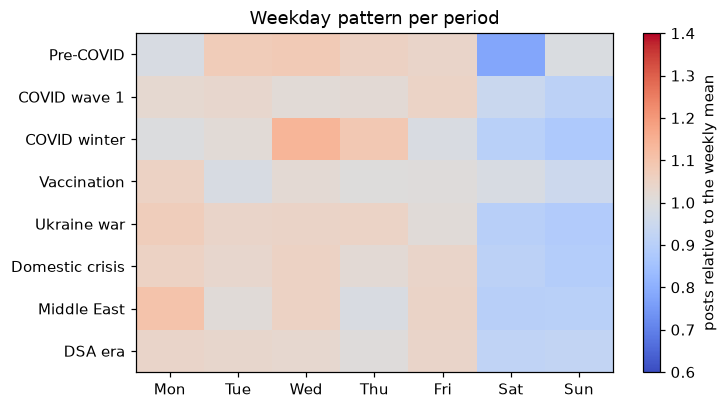

In [11]:
dow = daily.with_columns(pl.col("day").dt.weekday().alias("weekday"))
dow = assign_phase(dow, PHASES).filter(pl.col("phase").is_not_null())
tab = dow.group_by("phase", "weekday").agg(pl.col("n").mean()).to_pandas().pivot(index="phase", columns="weekday", values="n")
idx = tab.div(tab.mean(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7, 4)); im = ax.imshow(idx.to_numpy(), cmap="coolwarm", vmin=0.6, vmax=1.4, aspect="auto"); ax.grid(False)
ax.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax.set_yticks(range(len(idx)), idx.index)
plt.colorbar(im, label="posts relative to the weekly mean"); ax.set_title("Weekday pattern per period"); savefig("03_weekday"); plt.show()

## 6. Do the periods really differ? (tests)

With tens of thousands of posts almost any difference is "significant", so each test also reports an **effect size**.
Daily counts are autocorrelated and over-dispersed, which is why the regression below uses a Poisson model with
HAC standard errors (robust to both) and the plain tests are only a first look.

**6a. Kruskal-Wallis** on posts per active channel-day across periods (epsilon-squared = effect size, ~0.01 small, 0.06 medium, 0.14 large).

In [12]:
from scipy import stats
cd = assign_phase(daily_counts(df), PHASES).filter(pl.col("phase").is_not_null())
groups = [cd.filter(pl.col("phase") == ph)["n"].to_numpy() for ph in PHASES["phase"] if cd.filter(pl.col("phase") == ph).height > 0]
H, p = stats.kruskal(*groups)
k, n = len(groups), sum(len(g) for g in groups)
print(f"Kruskal-Wallis: H={H:.1f}, p={p:.3g}{' (below float precision)' if p == 0 else ''}, epsilon^2={(H - k + 1) / (n - k):.3f}  (k={k} periods, n={n:,} channel-days)")

names = [ph for ph in PHASES["phase"] if cd.filter(pl.col("phase") == ph).height > 0]
rows = []
for a, b in zip(names[:-1], names[1:]):
    x, y = cd.filter(pl.col("phase") == a)["n"].to_numpy(), cd.filter(pl.col("phase") == b)["n"].to_numpy()
    u, pu = stats.mannwhitneyu(x, y)
    rows.append({"from": a, "to": b, "median_from": np.median(x), "median_to": np.median(y), "mean_from": x.mean().round(2), "mean_to": y.mean().round(2),
                 "p_raw": pu, "prob_to_gt_from": round(1 - u / (len(x) * len(y)), 3)})
adj = holm_table([{"hypothesis": "adjacent", "test": f"{r['from']}->{r['to']}", "p": r["p_raw"]} for r in rows])
out = pd.DataFrame(rows).assign(p_holm=adj["p_holm"].to_numpy())
out

Kruskal-Wallis: H=98.8, p=1.9e-18, epsilon^2=0.002  (k=8 periods, n=39,267 channel-days)


,from,to,median_from,median_to,mean_from,mean_to,p_raw,prob_to_gt_from,p_holm
0,Pre-COVID,COVID wave 1,6.0,9.0,18.47,27.08,0.000217,0.553,0.000867
1,COVID wave 1,COVID winter,9.0,11.0,27.08,31.71,0.001289,0.532,0.003868
2,COVID winter,Vaccination,11.0,9.0,31.71,27.22,0.000019,0.467,0.000131
3,Vaccination,Ukraine war,9.0,10.0,27.22,25.65,0.000152,0.522,0.000762
4,Ukraine war,Domestic crisis,10.0,10.0,25.65,21.07,0.006550,0.484,0.013100
5,Domestic crisis,Middle East,10.0,10.0,21.07,22.30,0.296652,0.508,0.296652
6,Middle East,DSA era,10.0,10.0,22.30,18.88,0.000081,0.475,0.000483


**6b. Share of posts without text** across periods (chi-squared + Cramer's V as effect size).

In [13]:
d = assign_phase(df.select("day", "has_text"), PHASES).filter(pl.col("phase").is_not_null())
ct = d.group_by("phase", "has_text").len().to_pandas().pivot(index="phase", columns="has_text", values="len").fillna(0)
chi2, p, dof, _ = stats.chi2_contingency(ct.to_numpy())
V = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
print(f"chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramer's V={V:.3f}  (V ~0.1 small, 0.3 medium)")
(ct.div(ct.sum(axis=1), axis=0).round(3))

chi2=3767.7, dof=7, p=0, Cramer's V=0.066  (V ~0.1 small, 0.3 medium)


has_text,False,True
phase,,
Pre-COVID,0.067,0.933
COVID wave 1,0.053,0.947
COVID winter,0.081,0.919
Vaccination,0.097,0.903
Ukraine war,0.126,0.874
Domestic crisis,0.117,0.883
Middle East,0.112,0.888
DSA era,0.130,0.870


**6c. Regression: rate ratios per period** (reference = first period), controlling for weekday and for the number of
active channels (as exposure). Separate models for posts with text and without text. A ratio of 1.5 means 50 % more
posts per active channel-day than in the reference period.

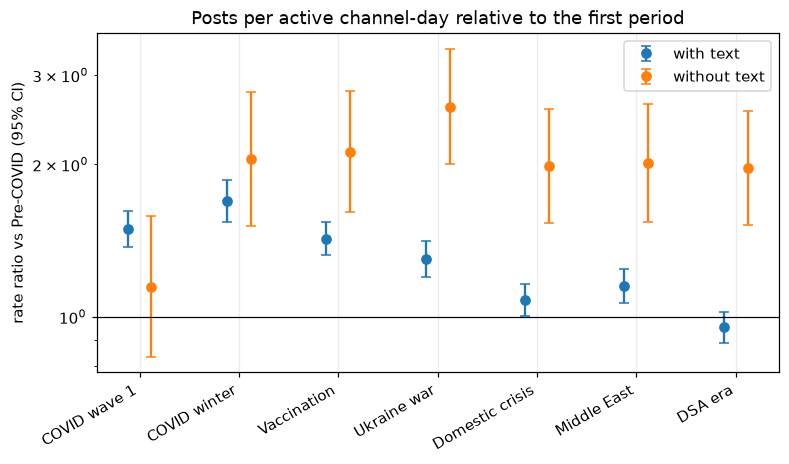

with text                      without text                \
                rate_ratio     lo     hi      p   rate_ratio     lo     hi   
phase                                                                        
COVID wave 1         1.490  1.372  1.617  0.000        1.148  0.835  1.580   
COVID winter         1.694  1.540  1.863  0.000        2.053  1.514  2.783   
Vaccination          1.427  1.324  1.537  0.000        2.122  1.610  2.795   
Ukraine war          1.301  1.199  1.412  0.000        2.603  2.001  3.387   
Domestic crisis      1.080  1.004  1.161  0.039        1.986  1.530  2.579   
Middle East          1.149  1.064  1.242  0.000        2.015  1.538  2.639   
DSA era              0.954  0.888  1.024  0.194        1.969  1.519  2.551   

                        
                     p  
phase                   
COVID wave 1     0.396  
COVID winter     0.000  
Vaccination      0.000  
Ukraine war      0.000  
Domestic crisis  0.000  
Middle East      0.000  
DSA era          0.000

In [14]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

dd = daily_counts(df)
daily_all = (dd.group_by("day").agg(pl.col("n").sum(), pl.col("n_text").sum(), pl.col("n_notext").sum(), pl.len().alias("active")).sort("day"))
pdd = assign_phase(daily_all, PHASES).filter(pl.col("phase").is_not_null()).to_pandas()
pdd["dow"] = pd.to_datetime(pdd["day"]).dt.dayofweek
ref = [ph for ph in PHASES["phase"] if ph in set(pdd["phase"])][0]

def phase_rr(y):
    res = smf.glm(f"{y} ~ C(phase, Treatment('{ref}')) + C(dow)", pdd, family=sm.families.Poisson(),
                  offset=np.log(pdd["active"])).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    ci = res.conf_int()
    rows = []
    for name in res.params.index:
        if name.startswith("C(phase"):
            ph = name.split("T.")[1].rstrip("]")
            rows.append({"phase": ph, "rate_ratio": np.exp(res.params[name]), "lo": np.exp(ci.loc[name, 0]), "hi": np.exp(ci.loc[name, 1]), "p": res.pvalues[name]})
    return pd.DataFrame(rows).set_index("phase")

rr = {"with text": phase_rr("n_text"), "without text": phase_rr("n_notext")}
fig, ax = plt.subplots(figsize=(8, 4))
for off, (lab, t) in zip((-0.12, 0.12), rr.items()):
    x = np.arange(len(t)) + off
    ax.errorbar(x, t["rate_ratio"], yerr=[t["rate_ratio"] - t["lo"], t["hi"] - t["rate_ratio"]], fmt="o", capsize=3, label=lab)
ax.axhline(1, color="k", lw=0.8); ax.set_xticks(range(len(rr["with text"])), rr["with text"].index, rotation=30, ha="right")
ax.set_yscale("log"); ax.set_ylabel(f"rate ratio vs {ref} (95% CI)"); ax.legend(); ax.set_title("Posts per active channel-day relative to the first period")
savefig("03_rate_ratios"); plt.show()
pd.concat(rr, axis=1).round(3)

## Notes and cautions
* **Survivor bias**: only channels that still exist (and are in `channels.txt`) are in the data.
* **Reach vs. volume**: many posts do not mean many readers - compare with views per post (notebook 01).
* Posts without text are not "empty": photos, videos, forwards. They are counted separately because tools like keyword analysis only see the text posts.
* Periods are theory-driven (research plan); the calendar quarters above are a neutral alternative.